### Setup & Imports

In [1]:
# ML Models Notebook - NU Sales Analytics
# Trains 5 models: Linear Regression, Random Forest, K-Means, Logistic Regression, Isolation Forest

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy import inspect

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score
)
from sklearn.preprocessing import StandardScaler

# Notebook display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

print("✅ All libraries loaded")

✅ All libraries loaded


In [2]:
load_dotenv()
engine = create_engine(f"postgresql://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}")


In [4]:
inspector = inspect(engine)
tables = inspector.get_table_names()
for table in tables:
    print(f"Table: {table}")

Table: pos_sales_data
Table: sales
Table: students
Table: marks
Table: sub_marks
Table: product_tbl
Table: order_tbl


In [5]:
df = pd.read_sql_table("sales", engine, schema="public")
df.head()

,Date,Transaction ID,Invoice No,Invoice type,Customer Name,Customer ID,Customer Type,Barcode,Product Name,Product Category,Sales by,Sales ID,Sales Zone,Zone Code,Sales Channel,Purchase Value,Invoice Value,Discount,Sales Amount,Sales VAT,Sales Return,Credited Amount,Payment Method,Bank Name,Remarks,Month Name
0,2025-03-09,TXN100001,INV10001,Cash Sale,M/S Nazma Store Store,CUST0106,Online,8834993708224,Wall Clock 2,Gift Items,Mynuddin Hasan Hridoy,EMP013,Gulshan,ZON013,Phone,"5,856.63","7,372.68","1,105.90","6,266.78",0.00,0.00,"6,266.78",Bkash,None,Advance Payment,March
1,2025-05-20,TXN100002,INV10002,Credit Sale,M/S Mohammadia Trading Store,CUST0155,Wholesale,8817094232227,Photo Frame 3,Gift Items,Jahirul Hoque Pranto,EMP005,Jatrabari,ZON005,Field,"33,556.80","51,918.40",0.00,"51,918.40",0.00,0.00,0.00,Cash,None,Regular Sale,May
2,2025-09-11,TXN100003,INV10003,Credit Sale,M/S Sajid & Brothers Store,CUST0195,Wholesale,8864775758589,Gift Box 2,Gift Items,Karim Ahmed,EMP011,Dhanmondi,ZON011,Phone,163.86,220.45,11.02,209.43,0.00,0.00,0.00,Cash,None,Special Discount,September
3,2025-06-14,TXN100004,INV10004,Cash Sale,M/S Kagotia Crockeries Store,CUST0119,Online,8830160360945,Fan 2,Electronics,Mynuddin Hasan Hridoy,EMP013,Gulshan,ZON013,Direct,"4,751.80","6,123.60",122.47,"6,001.13",300.06,0.00,0.00,Cash,None,Wholesale Order,June
4,2025-01-16,TXN100005,INV10005,Corporate Order,M/S Daniel Wagner Construction,CUST0058,Corporate,8879637317274,Electric Kettle 4,Electronics,ATM Noor Hossen Rumel,EMP006,Demra,ZON006,Phone,"3,377.12","4,723.06",0.00,"4,723.06",236.15,0.00,"1,487.76",Cash,None,Repeat Customer,January


### Data Cleaning & Feature Engineering

In [6]:
# Convert Date
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date']).reset_index(drop=True)

# Numeric columns
for col in ['Sales Amount', 'Purchase Value', 'Invoice Value', 'Discount',
            'Sales VAT', 'Sales Return', 'Credited Amount']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Derived columns
df['Gross Profit'] = df['Sales Amount'] - df['Purchase Value']
df['Market Due'] = df['Invoice Value'] - df['Sales Amount']
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Start'] = pd.to_datetime(df['Date'].dt.strftime('%Y-%m-01'), format='%Y-%m-%d')

print(f"✅ Data cleaned. Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Total Revenue: ৳{df['Sales Amount'].sum():,.0f}")
print(f"Total Profit:  ৳{df['Gross Profit'].sum():,.0f}")

✅ Data cleaned. Date range: 2025-01-01 to 2025-12-31
Total Revenue: ৳129,916,305
Total Profit:  ৳34,917,181


### Linear Regression: Monthly Sales Forecast

In [7]:
# ---- MODEL 1: LINEAR REGRESSION ----
print("=" * 60)
print("MODEL 1: LINEAR REGRESSION — Monthly Sales Forecast")
print("=" * 60)

# Aggregate monthly
monthly = df.groupby('Month_Start')['Sales Amount'].sum().reset_index().sort_values('Month_Start')
monthly['Index'] = np.arange(len(monthly))

# Train/test split (80/20)
X = monthly[['Index']].values
y = monthly['Sales Amount'].values
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Fit
model_lr = LinearRegression().fit(X_train, y_train)
y_pred = model_lr.predict(X_test)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred) if len(y_test) > 1 else 0

print(f"\n📊 Model Performance:")
print(f"   MAE:        ৳{mae:,.0f}")
print(f"   RMSE:       ৳{rmse:,.0f}")
print(f"   R² Score:   {r2:.4f}")
print(f"   Trend:      ৳{model_lr.coef_[0]:,.0f} / month")
print(f"   Intercept:  ৳{model_lr.intercept_:,.0f}")
print(f"\n📐 Equation: Sales = {model_lr.intercept_:,.0f} + {model_lr.coef_[0]:,.0f} × Month")

MODEL 1: LINEAR REGRESSION — Monthly Sales Forecast

📊 Model Performance:
   MAE:        ৳2,136,191
   RMSE:       ৳2,220,552
   R² Score:   -0.3501
   Trend:      ৳-40,796 / month
   Intercept:  ৳11,323,055

📐 Equation: Sales = 11,323,055 + -40,796 × Month


### Linear Regression Visualization

C:\Users\Mujakkir\AppData\Local\Temp\ipykernel_6932\321159511.py:10: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\Mujakkir\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


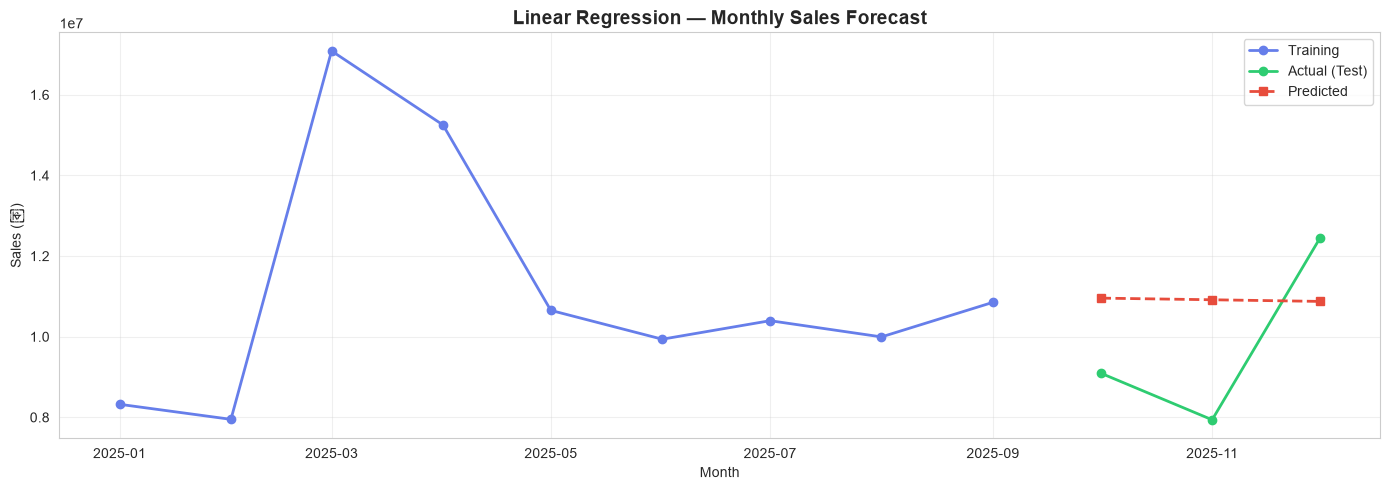

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly['Month_Start'][:split], y_train, 'o-', color='#667eea', label='Training', linewidth=2)
ax.plot(monthly['Month_Start'][split:], y_test, 'o-', color='#2ecc71', label='Actual (Test)', linewidth=2)
ax.plot(monthly['Month_Start'][split:], y_pred, 's--', color='#e74c3c', label='Predicted', linewidth=2)
ax.set_title('Linear Regression — Monthly Sales Forecast', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Sales (৳)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

###  Random Forest: Lag-Based Forecast

In [9]:
# ---- MODEL 2: RANDOM FOREST ----
print("=" * 60)
print("MODEL 2: RANDOM FOREST — Monthly Sales Forecast")
print("=" * 60)

# Feature engineering with lags
rf_df = monthly.copy()
rf_df['Lag1'] = rf_df['Sales Amount'].shift(1)
rf_df['Lag2'] = rf_df['Sales Amount'].shift(2)
rf_df['Rolling3'] = rf_df['Sales Amount'].rolling(3).mean()
rf_df = rf_df.dropna().reset_index(drop=True)

features = ['Lag1', 'Lag2', 'Rolling3']
X = rf_df[features].values
y = rf_df['Sales Amount'].values

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Fit
model_rf = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

# Metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf) if len(y_test) > 1 else 0

print(f"\n📊 Model Performance:")
print(f"   MAE:        ৳{mae_rf:,.0f}")
print(f"   RMSE:       ৳{rmse_rf:,.0f}")
print(f"   R² Score:   {r2_rf:.4f}")

print(f"\n🔍 Feature Importance:")
for f, imp in sorted(zip(features, model_rf.feature_importances_), key=lambda x: -x[1]):
    print(f"   {f:12} : {imp:.4f}")

MODEL 2: RANDOM FOREST — Monthly Sales Forecast

📊 Model Performance:
   MAE:        ৳2,092,331
   RMSE:       ৳2,092,952
   R² Score:   0.1372

🔍 Feature Importance:
   Lag2         : 0.6945
   Lag1         : 0.1974
   Rolling3     : 0.1081


### Random Forest Visualization

C:\Users\Mujakkir\AppData\Local\Temp\ipykernel_6932\2101677281.py:20: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\Mujakkir\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


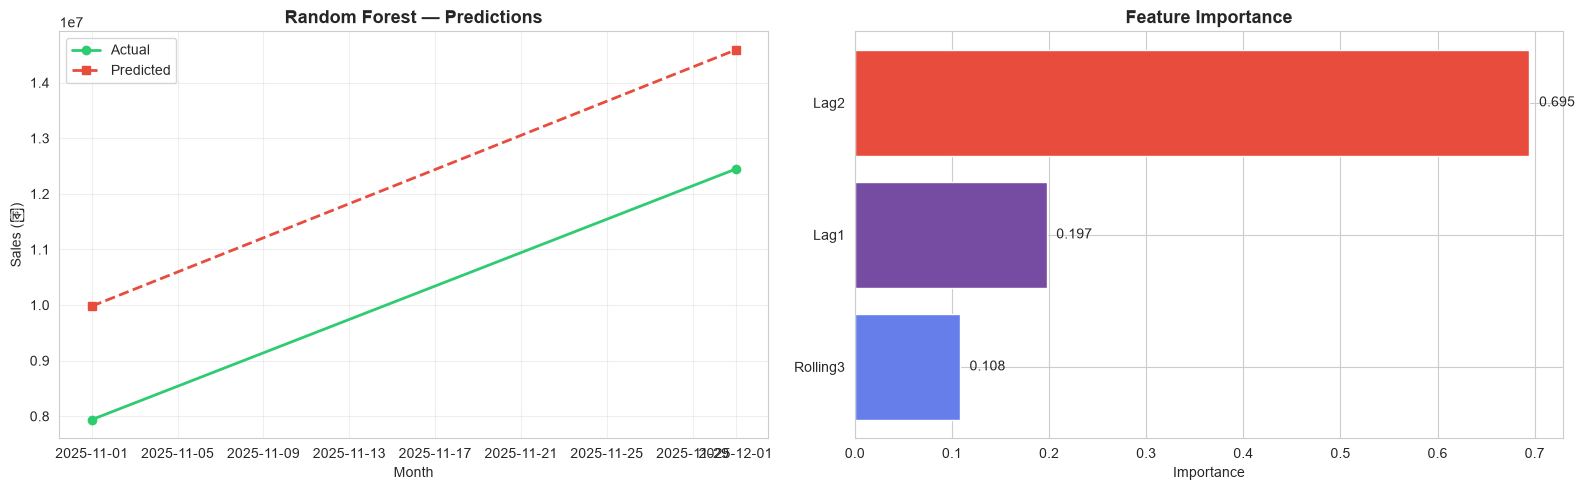

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Predicted vs Actual
axes[0].plot(rf_df['Month_Start'][split:], y_test, 'o-', color='#2ecc71', label='Actual', linewidth=2)
axes[0].plot(rf_df['Month_Start'][split:], y_pred_rf, 's--', color='#e74c3c', label='Predicted', linewidth=2)
axes[0].set_title('Random Forest — Predictions', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Sales (৳)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Feature importance
imp_df = pd.DataFrame({'Feature': features, 'Importance': model_rf.feature_importances_}).sort_values('Importance')
axes[1].barh(imp_df['Feature'], imp_df['Importance'], color=['#667eea', '#764ba2', '#e74c3c'][:len(imp_df)])
axes[1].set_title('Feature Importance', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Importance')
for i, v in enumerate(imp_df['Importance']):
    axes[1].text(v + 0.01, i, f'{v:.3f}', va='center')

plt.tight_layout()
plt.show()

### K-Means Customer Clustering

In [11]:
# ---- MODEL 3: K-MEANS CLUSTERING ----
print("=" * 60)
print("MODEL 3: K-MEANS — Customer Clustering (RFM)")
print("=" * 60)

# Build RFM
ref_date = df['Date'].max()
rfm = df.groupby('Customer Name').agg({
    'Date': lambda x: (ref_date - x.max()).days,
    'Invoice No': 'nunique',
    'Sales Amount': 'sum'
}).reset_index()
rfm.columns = ['Customer', 'Recency', 'Frequency', 'Monetary']

print(f"\n📊 RFM Summary:")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(1))

# Determine optimal K using Elbow Method
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

inertias = []
sil_scores = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

print(f"\n📊 Silhouette Scores:")
for k, s in zip(K_range, sil_scores):
    print(f"   K={k}: {s:.4f}")

MODEL 3: K-MEANS — Customer Clustering (RFM)

📊 RFM Summary:
       Recency  Frequency   Monetary
count   264.00     264.00     264.00
mean     22.00      72.00 492,107.20
std      37.90      11.30 115,977.30
min       0.00      36.00 248,641.30
25%       1.00      64.80 413,368.30
50%       3.00      73.00 489,859.80
75%       9.20      80.20 557,865.40
max     126.00     102.00 804,114.00

📊 Silhouette Scores:
   K=2: 0.5844
   K=3: 0.4421
   K=4: 0.3941
   K=5: 0.4023
   K=6: 0.3839
   K=7: 0.3570
   K=8: 0.3322


### K-Means Visualization & Final Clusters

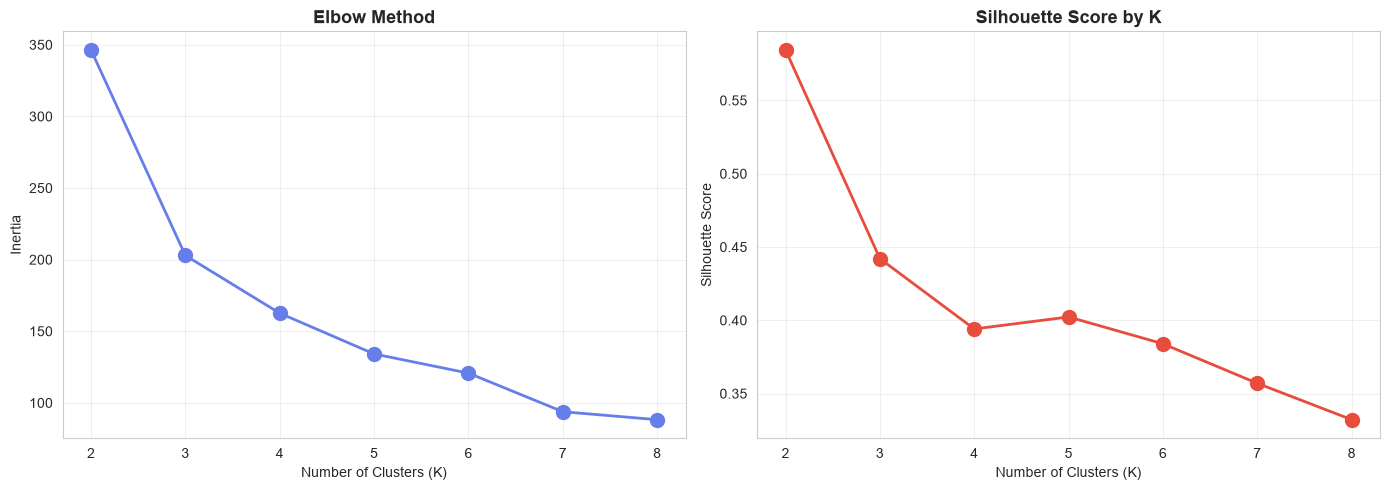


✅ Best K = 2 (Silhouette = 0.5844)

📊 Cluster Profiles:
         Customers  Avg Recency  Avg Frequency  Avg Monetary
Cluster                                                     
0               54        95.40          56.70    378,470.30
1              210         3.10          75.90    521,328.10


In [12]:
# Plot elbow + silhouette
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'o-', color='#667eea', linewidth=2, markersize=10)
axes[0].set_title('Elbow Method', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)

axes[1].plot(K_range, sil_scores, 'o-', color='#e74c3c', linewidth=2, markersize=10)
axes[1].set_title('Silhouette Score by K', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Use best K (highest silhouette)
best_k = K_range[np.argmax(sil_scores)]
print(f"\n✅ Best K = {best_k} (Silhouette = {max(sil_scores):.4f})")

# Final model
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
rfm['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Cluster profiles
summary = rfm.groupby('Cluster').agg({
    'Customer': 'count',
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(1)
summary.columns = ['Customers', 'Avg Recency', 'Avg Frequency', 'Avg Monetary']
print("\n📊 Cluster Profiles:")
print(summary)

### K-Means 3D Scatter

c:\Users\Mujakkir\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


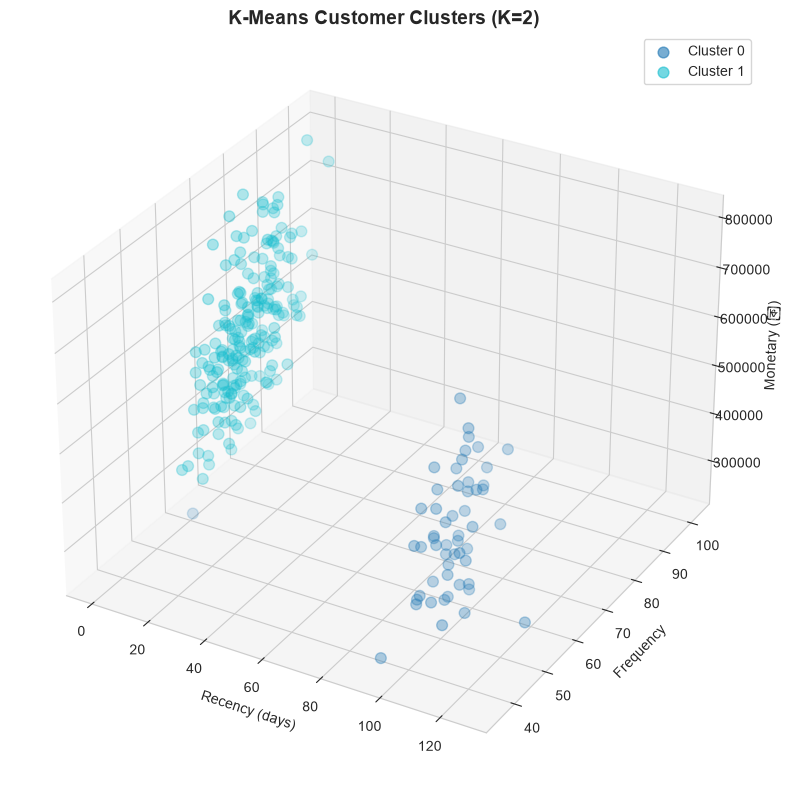

In [13]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

colors = plt.cm.tab10(np.linspace(0, 1, best_k))
for cluster_id in range(best_k):
    cluster_data = rfm[rfm['Cluster'] == cluster_id]
    ax.scatter(
        cluster_data['Recency'],
        cluster_data['Frequency'],
        cluster_data['Monetary'],
        s=60, alpha=0.6, color=colors[cluster_id], label=f'Cluster {cluster_id}'
    )

ax.set_xlabel('Recency (days)')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary (৳)')
ax.set_title(f'K-Means Customer Clusters (K={best_k})', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### Logistic Regression (High-Value Product Classifier)

In [14]:
# ---- MODEL 4: LOGISTIC REGRESSION ----
print("=" * 60)
print("MODEL 4: LOGISTIC REGRESSION — High-Value Product Classifier")
print("=" * 60)

# Build product-level features
prod = df.groupby('Product Name').agg({
    'Sales Amount': 'sum',
    'Purchase Value': 'sum',
    'Discount': 'mean',
    'Invoice No': 'nunique'
}).reset_index()
prod.columns = ['Product', 'Revenue', 'Cost', 'Avg_Discount', 'Orders']
prod['Profit'] = prod['Revenue'] - prod['Cost']
prod['Margin'] = np.where(prod['Revenue'] > 0, prod['Profit'] / prod['Revenue'], 0)

# Binary label: top 30% by revenue = high-value
threshold = prod['Revenue'].quantile(0.7)
prod['Is_High_Value'] = (prod['Revenue'] >= threshold).astype(int)

print(f"\n📊 Class Distribution:")
print(f"   High-value products: {prod['Is_High_Value'].sum()} / {len(prod)} ({prod['Is_High_Value'].mean()*100:.1f}%)")
print(f"   Revenue threshold:   ৳{threshold:,.0f}")

# Split
features = ['Cost', 'Avg_Discount', 'Orders', 'Margin']
X = prod[features].values
y = prod['Is_High_Value'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit
model_logreg = LogisticRegression(max_iter=1000, random_state=42)
model_logreg.fit(X_train, y_train)
y_pred = model_logreg.predict(X_test)

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"\n📊 Model Performance:")
print(f"   Accuracy:  {acc:.4f}")
print(f"   Precision: {prec:.4f}")
print(f"   Recall:    {rec:.4f}")
print(f"   F1 Score:  {f1:.4f}")

print(f"\n🔍 Feature Coefficients:")
for f, c in sorted(zip(features, model_logreg.coef_[0]), key=lambda x: -abs(x[1])):
    print(f"   {f:15} : {c:+.4f}")

MODEL 4: LOGISTIC REGRESSION — High-Value Product Classifier

📊 Class Distribution:
   High-value products: 38 / 125 (30.4%)
   Revenue threshold:   ৳1,468,926

📊 Model Performance:
   Accuracy:  0.9600
   Precision: 1.0000
   Recall:    0.8750
   F1 Score:  0.9333

🔍 Feature Coefficients:
   Orders          : -0.1037
   Avg_Discount    : +0.0075
   Margin          : -0.0001
   Cost            : +0.0000


### Confusion Matrix & Coefficients

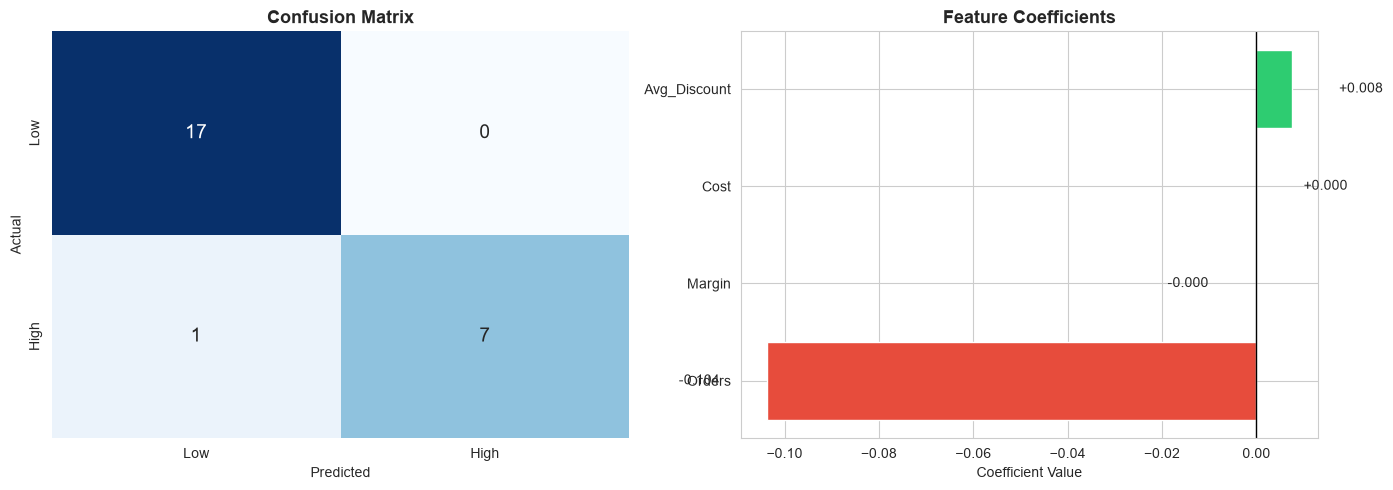

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'],
            cbar=False, ax=axes[0], annot_kws={'size': 14})
axes[0].set_title('Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Coefficients
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': model_logreg.coef_[0]}).sort_values('Coefficient')
colors_coef = ['#e74c3c' if c < 0 else '#2ecc71' for c in coef_df['Coefficient']]
axes[1].barh(coef_df['Feature'], coef_df['Coefficient'], color=colors_coef)
axes[1].axvline(x=0, color='black', linewidth=1)
axes[1].set_title('Feature Coefficients', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Coefficient Value')
for i, v in enumerate(coef_df['Coefficient']):
    axes[1].text(v + (0.01 if v >= 0 else -0.01), i, f'{v:+.3f}',
                 va='center', ha='left' if v >= 0 else 'right')

plt.tight_layout()
plt.show()

### Isolation Forest (Anomaly Detection)

In [16]:
# ---- MODEL 5: ISOLATION FOREST ----
print("=" * 60)
print("MODEL 5: ISOLATION FOREST — Anomaly Detection")
print("=" * 60)

# Aggregate by invoice
inv = df.groupby('Invoice No').agg({
    'Sales Amount': 'sum',
    'Discount': 'sum',
    'Sales Return': 'sum',
    'Market Due': 'sum',
    'Product Name': 'count'
}).reset_index()
inv.columns = ['Invoice No', 'Sales', 'Discount', 'Returns', 'Due', 'Items']

print(f"\n📊 Total Invoices: {len(inv):,}")

# Features for anomaly detection
features = ['Sales', 'Discount', 'Returns', 'Due', 'Items']
X = inv[features].values

# Fit Isolation Forest
contamination = 0.05  # expect ~5% anomalies
model_if = IsolationForest(contamination=contamination, random_state=42, n_estimators=200)
inv['Anomaly'] = model_if.fit_predict(X)
inv['Anomaly_Label'] = np.where(inv['Anomaly'] == -1, 'Anomaly', 'Normal')
inv['Anomaly_Score'] = -model_if.score_samples(X)

n_anomalies = (inv['Anomaly'] == -1).sum()
print(f"\n📊 Detection Results:")
print(f"   Contamination rate: {contamination*100:.1f}%")
print(f"   Anomalies detected: {n_anomalies:,} ({n_anomalies/len(inv)*100:.2f}%)")
print(f"   Normal invoices:    {len(inv) - n_anomalies:,}")

print(f"\n🚨 Top 10 Most Anomalous Invoices:")
top_anomalies = inv[inv['Anomaly'] == -1].nlargest(10, 'Anomaly_Score')[
    ['Invoice No', 'Sales', 'Discount', 'Returns', 'Due', 'Items', 'Anomaly_Score']
]
print(top_anomalies.to_string(index=False))

MODEL 5: ISOLATION FOREST — Anomaly Detection

📊 Total Invoices: 19,002

📊 Detection Results:
   Contamination rate: 5.0%
   Anomalies detected: 949 (4.99%)
   Normal invoices:    18,053

🚨 Top 10 Most Anomalous Invoices:
Invoice No     Sales  Discount   Returns       Due  Items  Anomaly_Score
  INV11619 61,338.04 10,824.36 15,121.95 10,824.36      1           0.85
  INV13853 61,338.04 10,824.36  8,869.90 10,824.36      1           0.85
  INV15447 64,171.44  7,130.16 11,325.16  7,130.16      1           0.84
  INV10788 51,203.32  9,035.88  8,665.54  9,035.88      1           0.84
  INV11673 53,794.63  9,493.17  7,167.21  9,493.17      1           0.84
  INV14972 65,597.47  5,704.13 10,831.76  5,704.13      1           0.84
  INV12170 43,854.05  7,738.95  9,320.67  7,738.95      1           0.83
  INV16900 51,775.56  5,752.84  9,693.29  5,752.84      1           0.83
  INV28758 51,775.56  5,752.84 13,022.67  5,752.84      1           0.83
  INV15997 43,530.54  7,681.86  7,943.80  7,681.

### Isolation Forest Visualization

C:\Users\Mujakkir\AppData\Local\Temp\ipykernel_6932\3918177541.py:25: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\Mujakkir\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 2547 (\N{BENGALI RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


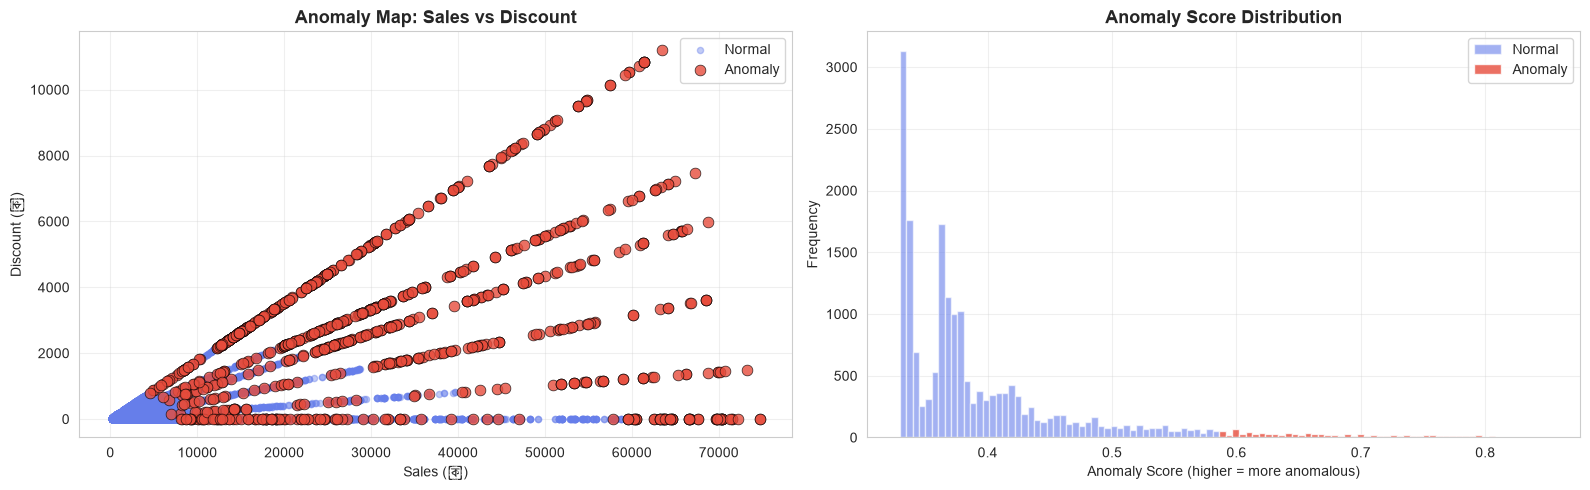

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: Sales vs Discount, colored by anomaly
normal = inv[inv['Anomaly'] == 1]
anomaly = inv[inv['Anomaly'] == -1]

axes[0].scatter(normal['Sales'], normal['Discount'], alpha=0.4, s=20, color='#667eea', label='Normal')
axes[0].scatter(anomaly['Sales'], anomaly['Discount'], alpha=0.8, s=60, color='#e74c3c',
                edgecolors='black', linewidth=0.5, label='Anomaly')
axes[0].set_title('Anomaly Map: Sales vs Discount', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sales (৳)')
axes[0].set_ylabel('Discount (৳)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Distribution of anomaly scores
axes[1].hist(normal['Anomaly_Score'], bins=50, alpha=0.6, color='#667eea', label='Normal')
axes[1].hist(anomaly['Anomaly_Score'], bins=50, alpha=0.8, color='#e74c3c', label='Anomaly')
axes[1].set_title('Anomaly Score Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Anomaly Score (higher = more anomalous)')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Model Comparison Summary

In [18]:
print("=" * 60)
print("📊 FINAL MODEL SUMMARY")
print("=" * 60)

summary_data = {
    'Model': [
        'Linear Regression',
        'Random Forest',
        'K-Means Clustering',
        'Logistic Regression',
        'Isolation Forest'
    ],
    'Task': [
        'Regression',
        'Regression',
        'Clustering',
        'Classification',
        'Anomaly Detection'
    ],
    'Primary Metric': [
        f'R² = {r2:.3f}',
        f'R² = {r2_rf:.3f}',
        f'Silhouette = {max(sil_scores):.3f}',
        f'F1 = {f1:.3f}',
        f'{n_anomalies:,} anomalies'
    ]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

print("\n" + "=" * 60)
print("✅ All 5 models trained and evaluated successfully!")
print("=" * 60)

📊 FINAL MODEL SUMMARY
              Model              Task     Primary Metric
  Linear Regression        Regression        R² = -0.350
      Random Forest        Regression         R² = 0.137
 K-Means Clustering        Clustering Silhouette = 0.584
Logistic Regression    Classification         F1 = 0.933
   Isolation Forest Anomaly Detection      949 anomalies

✅ All 5 models trained and evaluated successfully!


###  Prophet: Time-Series Forecast

In [20]:
# ---- MODEL 6: PROPHET ----
print("=" * 60)
print("MODEL 6: PROPHET — Time-Series Forecast")
print("=" * 60)

from prophet import Prophet

# Prophet requires columns named 'ds' (date) and 'y' (value)
prophet_df = monthly[['Month_Start', 'Sales Amount']].copy()
prophet_df = prophet_df.rename(columns={'Month_Start': 'ds', 'Sales Amount': 'y'})
prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])

print(f"\n📊 Data prepared: {len(prophet_df)} months")
print(prophet_df.tail())

# Initialize and fit Prophet
# yearly_seasonality=True is default; we can explicitly set it
model_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,   # Monthly data doesn't have weekly patterns
    daily_seasonality=False,
    changepoint_prior_scale=0.05,  # Controls trend flexibility
    seasonality_mode='additive'
)
model_prophet.fit(prophet_df)

print("\n✅ Prophet model fitted successfully")

MODEL 6: PROPHET — Time-Series Forecast

📊 Data prepared: 12 months
           ds             y
7  2025-08-01  9,993,854.51
8  2025-09-01 10,851,152.17
9  2025-10-01  9,094,656.49
10 2025-11-01  7,938,136.49
11 2025-12-01 12,444,679.30


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:04:25 - cmdstanpy - INFO - Chain [1] start processing
15:04:31 - cmdstanpy - INFO - Chain [1] done processing



✅ Prophet model fitted successfully
